<a href="https://colab.research.google.com/github/JOk3r01001/Pipeline-approach-for-fracture-classification-using-YOLO-and-Keras/blob/main/pipeline_main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import drive


#Připojení Google Disku do prostředí Colab pro přístup k souborům
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install ultralytics
from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 12.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [11]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.efficientnet import preprocess_input
from ultralytics import YOLO
from PIL import Image, ImageFile
import cv2
from sklearn.metrics import classification_report, confusion_matrix
ImageFile.LOAD_TRUNCATED_IMAGES = True

# Cesty k datům
BASE_PATH = "/content/drive/MyDrive/BK2.0/FracAtlas2"
TEST_CSV = "/content/drive/MyDrive/YOLO_undersample/universal_test_split.csv"
YOLO_PATH = "/content/drive/MyDrive/YOLO_undersample/frac_atlas_seg_640_usample/weights/best.pt"
KERAS_PATH = "/content/drive/MyDrive/KerasNET/efficientnet_best.keras"
IMG_SIZE = (640, 640)
CONF_THRESHOLD = 0.05  # YOLO confidence

# Načtení modelů
print("Načítám modely...")
yolo_model = YOLO(YOLO_PATH)
keras_model = keras.models.load_model(KERAS_PATH)
print("Modely načteny!")

# Načtení testovacích dat
test_df = pd.read_csv(TEST_CSV)

def get_full_path(row):
    folder = 'Fractured' if row['label'] == 1 else 'Non_fractured'
    return os.path.join(BASE_PATH, 'images', folder, row['img_name'])

test_df['filepath'] = test_df.apply(get_full_path, axis=1)
print(f"Testovací snímky: {len(test_df)}")
print(f"  Zlomeniny: {test_df['label'].sum()}")
print(f"  Zdravé: {(test_df['label'] == 0).sum()}")

# Nastavení pipeline
TOP_K = 50          # kolik nejlepších boxů vyhodnotit
KERAS_TH = 0.25     # práh pro klasifikátor
PAD = 100           # padding kolem boxu 100

# Pipeline funce: YOLO detekce → výběr Top-K boxů → crop + padding → Keras klasifikace cropu → rozhodnutí
def run_pipeline(img_path, conf_threshold=CONF_THRESHOLD, top_k=TOP_K, keras_th=KERAS_TH, pad=PAD):
    img = cv2.imread(img_path)
    if img is None:
        return 0

    results = yolo_model(img_path, conf=conf_threshold, verbose=False)
    boxes = results[0].boxes
    if boxes is None or len(boxes) == 0:
        return 0

    confs = boxes.conf.detach().cpu().numpy()
    top_idx = np.argsort(confs)[::-1][:top_k]

    h, w = img.shape[:2]
    best_prob = 0.0

    for i in top_idx:
        box = boxes[i]
        x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())

        # Rozšíření boxu padding + ořez
        x1 = max(0, x1 - pad)
        y1 = max(0, y1 - pad)
        x2 = min(w, x2 + pad)
        y2 = min(h, y2 + pad)

        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            continue

        # Příprava cropu
        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        crop_resized = cv2.resize(crop_rgb, IMG_SIZE)
        crop_array = np.expand_dims(crop_resized.astype(np.float32), axis=0)
        crop_preprocessed = preprocess_input(crop_array)

        # Klasifikace
        prob = float(keras_model.predict(crop_preprocessed, verbose=0)[0][0])
        best_prob = max(best_prob, prob)

        if prob > keras_th:
            return 1

    return 1 if best_prob > keras_th else 0

# Spuštění pipeline na testovací sadě
print("\nSpouštím pipeline...")
y_true = []
y_pred = []
failed = 0

for idx, row in test_df.iterrows():
    try:
        pred = run_pipeline(row['filepath'])
        y_true.append(row['label'])
        y_pred.append(pred)
    except Exception as e:
        failed += 1
        continue

    if (idx + 1) % 50 == 0:
        print(f"  Zpracováno: {idx + 1}/{len(test_df)}")

print(f"\nDokončeno! Selhalo: {failed} snímků")

# Výsledky
print("VÝSLEDKY PIPELINE")
print(classification_report(
    y_true,
    y_pred,
    target_names=['No Fracture', 'Fracture']
))

cm = confusion_matrix(y_true, y_pred)
print("Matice záměn:")
print(cm)

Načítám modely...
Modely načteny!
Testovací snímky: 409
  Zlomeniny: 72
  Zdravé: 337

Spouštím pipeline...
  Zpracováno: 50/409
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/Non_fractured/IMG0004076.jpg
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/Non_fractured/IMG0004288.jpg
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/Non_fractured/IMG0004079.jpg
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/Non_fractured/IMG0004173.jpg
  Zpracováno: 100/409
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/Non_fractured/IMG0004142.jpg
  Zpracováno: 150/409
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/Non_fractured/IMG0004155.jpg
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/Non_fractured/IMG0004143.jpg
  Zpracováno: 200/409
WARNING ⚠️ Image Read Error /content/drive/MyDrive/BK2.0/FracAtlas2/images/No

Selected 6 test images

IMAGE 1: IMG0002603.jpg
Ground truth: 1
Prediction: 1
Max Keras probability: 0.8550
  Box 1: YOLO conf=0.4259 | Keras prob=0.8550
Saved: /content/drive/MyDrive/pipeline_examples/example_1_IMG0002603.png

IMAGE 2: IMG0002566.jpg
Ground truth: 1
Prediction: 1
Max Keras probability: 0.5838
  Box 1: YOLO conf=0.6700 | Keras prob=0.5838
Saved: /content/drive/MyDrive/pipeline_examples/example_2_IMG0002566.png

IMAGE 3: IMG0001008.jpg
Ground truth: 1
Prediction: 1
Max Keras probability: 0.7190
  Box 1: YOLO conf=0.6323 | Keras prob=0.7190
Saved: /content/drive/MyDrive/pipeline_examples/example_3_IMG0001008.png

IMAGE 4: IMG0002474.jpg
Ground truth: 1
Prediction: 1
Max Keras probability: 0.9787
  Box 1: YOLO conf=0.5098 | Keras prob=0.9787
Saved: /content/drive/MyDrive/pipeline_examples/example_4_IMG0002474.png

IMAGE 5: IMG0001627.jpg
Ground truth: 0
Prediction: 0
Max Keras probability: 0.0000
Saved: /content/drive/MyDrive/pipeline_examples/example_5_IMG0001627.png

IM

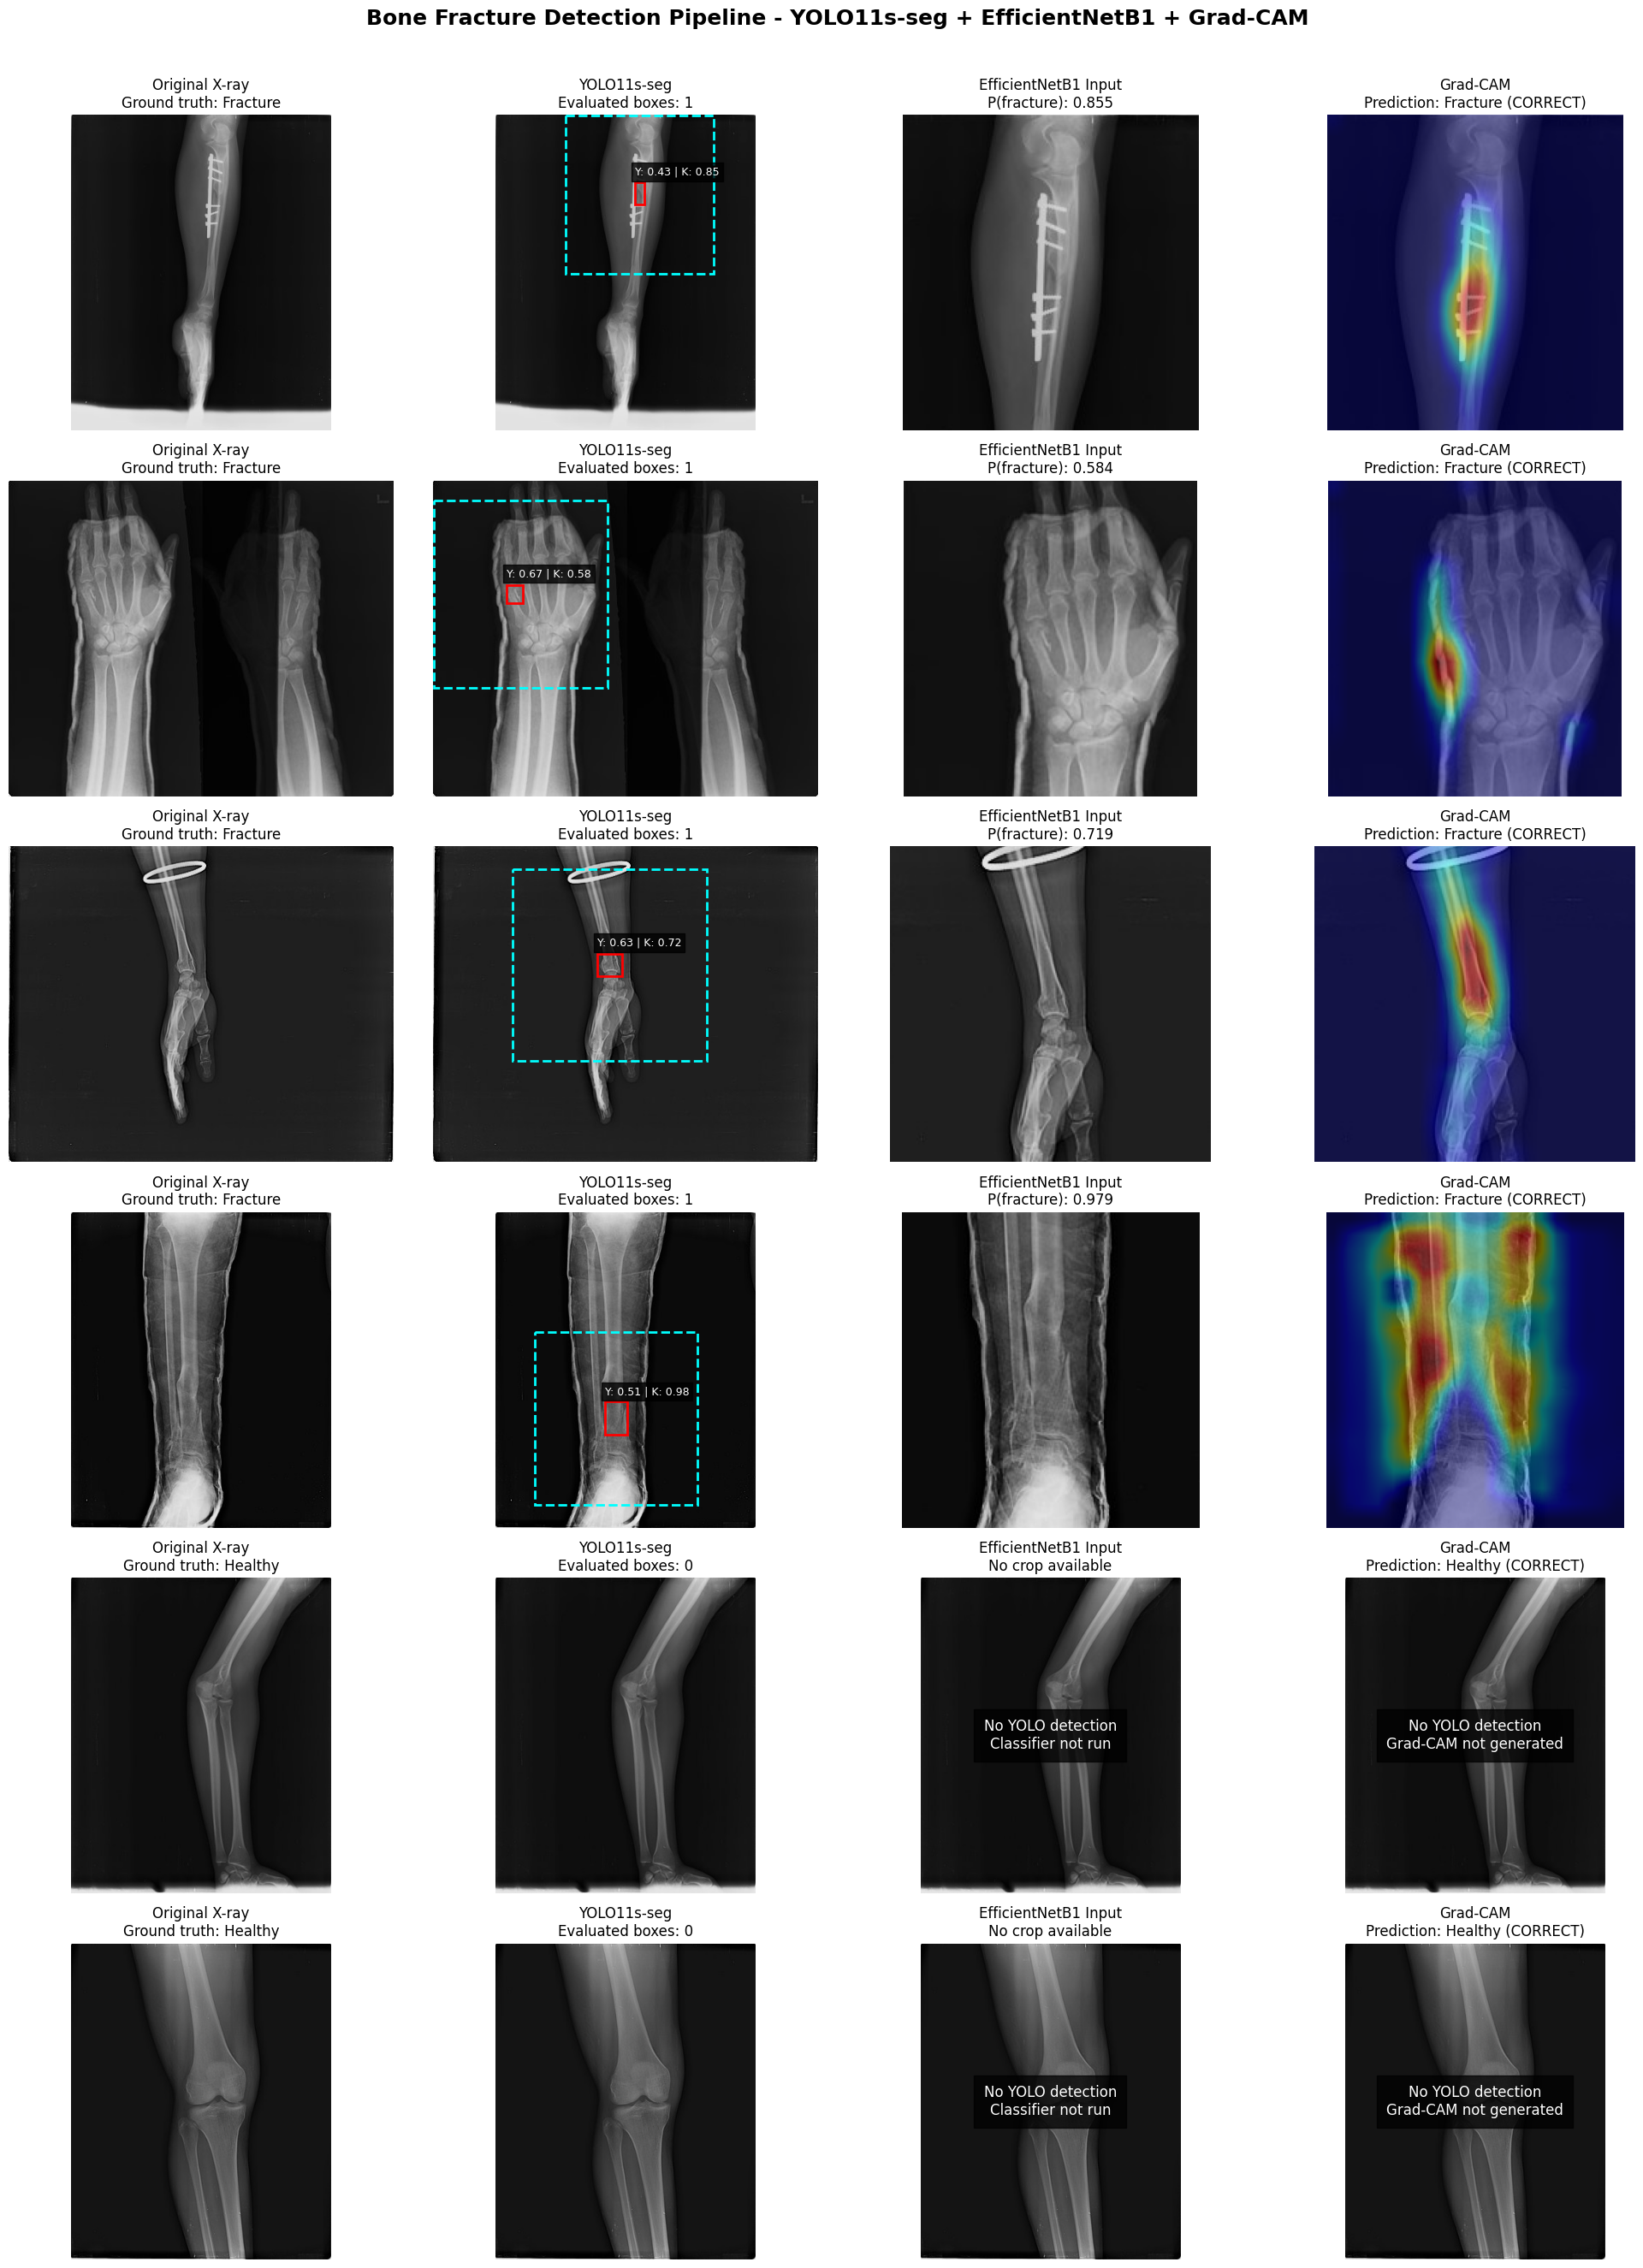


All visualizations saved!
Gallery: /content/drive/MyDrive/pipeline_examples/pipeline_gallery.png


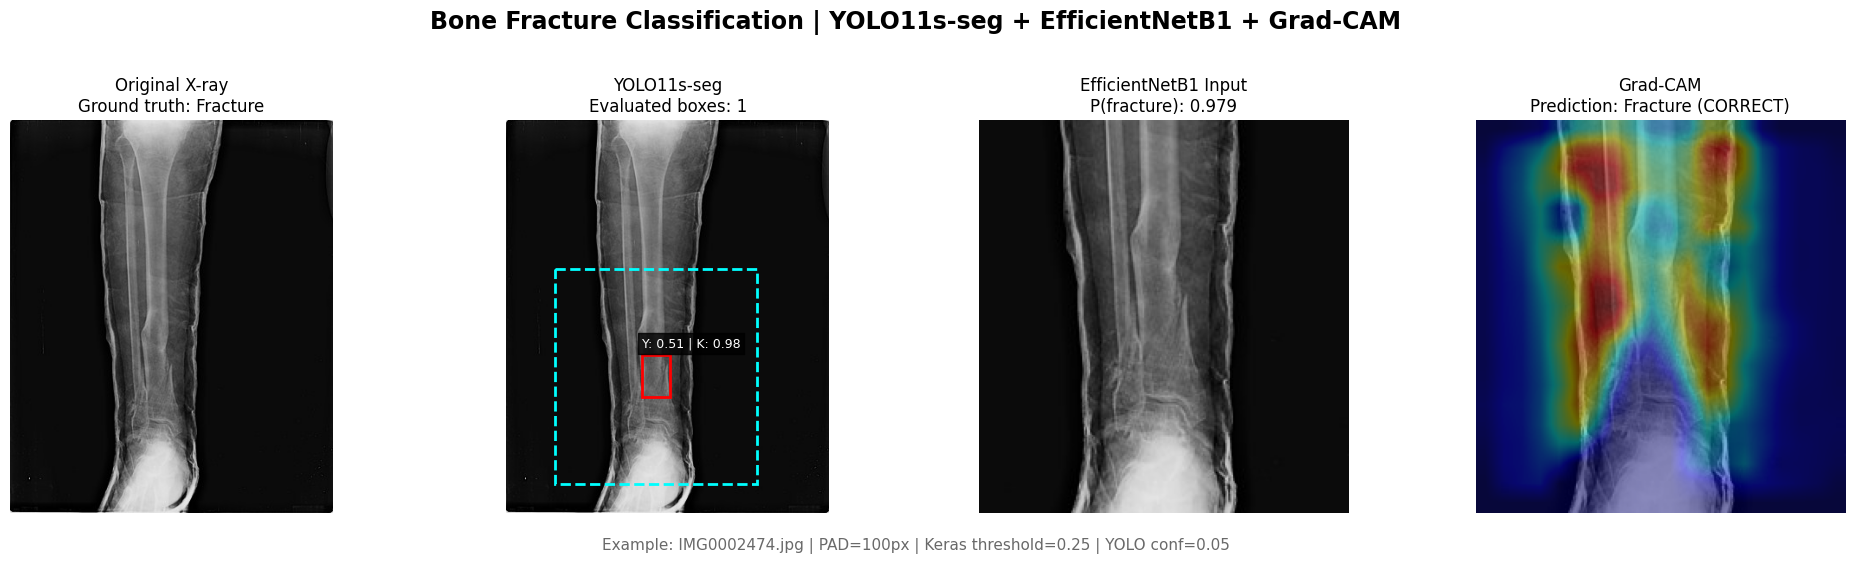

Profile showcase: /content/drive/MyDrive/pipeline_examples/profile_showcase.png
Selected X-ray: IMG0002474.jpg


In [14]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from matplotlib.patches import Rectangle
from tensorflow import keras
from tensorflow.keras.applications.efficientnet import preprocess_input
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

# ============================================================
# CONFIGURATION
# ============================================================

N_FRACTURED = 4
N_HEALTHY = 2

# For a GitHub profile / README showcase:
# None = automatically choose one correctly classified fractured X-ray.
# Alternatively, enter an exact filename from test_df, e.g. "IMG0000001.jpg".
PROFILE_IMAGE_NAME = None
PROFILE_SEARCH_LIMIT = 25  # extra fractured images to try if needed

OUTPUT_DIR = "/content/drive/MyDrive/pipeline_examples"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Uses existing:
# yolo_model, keras_model, test_df
# IMG_SIZE, CONF_THRESHOLD, TOP_K, KERAS_TH, PAD


# ============================================================
# 1. GRAD-CAM MODEL
# ============================================================

def create_gradcam_model(model):
    # Case A: EfficientNet layers are directly in the model
    try:
        conv_layer = model.get_layer("top_conv")

        extractor = keras.Model(
            inputs=model.inputs,
            outputs=[conv_layer.output, model.outputs[0]]
        )

        return extractor, None

    except (ValueError, AttributeError):
        pass

    # Case B: EfficientNet is a nested backbone
    for layer in model.layers:
        if isinstance(layer, keras.Model):
            try:
                conv_layer = layer.get_layer("top_conv")

                extractor = keras.Model(
                    inputs=layer.inputs,
                    outputs=[conv_layer.output, layer.outputs[0]]
                )

                return extractor, layer

            except (ValueError, AttributeError):
                continue

    raise ValueError(
        "Cannot find EfficientNet top_conv layer. "
        "Inspect keras_model.summary(expand_nested=True)."
    )


gradcam_model, backbone = create_gradcam_model(keras_model)


# ============================================================
# 2. GENERATE GRAD-CAM
# ============================================================

def generate_gradcam(crop_rgb):

    resized = cv2.resize(crop_rgb, IMG_SIZE)

    x = np.expand_dims(
        resized.astype(np.float32), axis=0
    )

    x = preprocess_input(x)

    with tf.GradientTape() as tape:

        conv_outputs, predictions = gradcam_model(
            x, training=False
        )

        # Pass backbone features through classification head
        if backbone is not None:

            passed_backbone = False

            for layer in keras_model.layers:

                if passed_backbone:
                    if isinstance(
                        layer,
                        (keras.layers.Dropout,
                         keras.layers.BatchNormalization)
                    ):
                        predictions = layer(
                            predictions, training=False
                        )
                    else:
                        predictions = layer(predictions)

                elif layer is backbone:
                    passed_backbone = True

        class_score = predictions[:, 0]

    grads = tape.gradient(class_score, conv_outputs)

    if grads is None:
        raise RuntimeError("Grad-CAM gradients unavailable.")

    # Global average pooling of gradients
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs[0] * weights,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    heatmap = heatmap.numpy()

    # Resize to original crop size
    heatmap = cv2.resize(
        heatmap,
        (crop_rgb.shape[1], crop_rgb.shape[0])
    )

    # Apply colormap
    heatmap_color = cv2.applyColorMap(
        np.uint8(255 * heatmap),
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color, cv2.COLOR_BGR2RGB
    )

    # Overlay
    overlay = cv2.addWeighted(
        crop_rgb,
        0.6,
        heatmap_color,
        0.4,
        0
    )

    return overlay


# ============================================================
# 3. PIPELINE INFERENCE WITH DETAILS
# ============================================================

def read_xray(img_path):
    """Read as BGR, with Pillow fallback for difficult JPEG files."""
    img = cv2.imread(img_path)
    if img is not None:
        return img

    print(f"OpenCV could not read {img_path}; trying Pillow")
    try:
        with Image.open(img_path) as pil_img:
            rgb = np.asarray(pil_img.convert("RGB"))
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    except Exception as exc:
        raise ValueError(f"Cannot read image: {img_path}") from exc


def evaluate_image(img_path):

    img = read_xray(img_path)

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]

    # Pass the already decoded image to avoid a second file read by YOLO.
    results = yolo_model(
        img,
        conf=CONF_THRESHOLD,
        verbose=False
    )

    if not results:
        raise RuntimeError(f"YOLO returned no results for {img_path}")

    boxes = results[0].boxes

    detections = []
    best_prob = 0.0
    best_crop = None
    best_detection = None

    if boxes is not None and len(boxes) > 0:

        confidences = boxes.conf.cpu().numpy()
        indices = np.argsort(confidences)[::-1][:TOP_K]

        for i in indices:

            box = boxes[int(i)]

            yolo_conf = float(box.conf[0].item())

            x1, y1, x2, y2 = map(
                int, box.xyxy[0].cpu().numpy()
            )

            # Same padding as original pipeline
            px1 = max(0, x1 - PAD)
            py1 = max(0, y1 - PAD)
            px2 = min(w, x2 + PAD)
            py2 = min(h, y2 + PAD)

            crop = img[py1:py2, px1:px2]

            if crop.size == 0:
                continue

            crop_rgb = cv2.cvtColor(
                crop, cv2.COLOR_BGR2RGB
            )

            resized = cv2.resize(crop_rgb, IMG_SIZE)

            x = np.expand_dims(
                resized.astype(np.float32), axis=0
            )

            x = preprocess_input(x)

            keras_prob = float(
                keras_model.predict(x, verbose=0)[0][0]
            )

            detection = {
                "box": (x1, y1, x2, y2),
                "padded_box": (px1, py1, px2, py2),
                "yolo_conf": yolo_conf,
                "keras_prob": keras_prob
            }

            detections.append(detection)

            if best_crop is None or keras_prob > best_prob:
                best_prob = keras_prob
                best_crop = crop_rgb
                best_detection = detection

            # Preserve original pipeline early stopping
            if keras_prob > KERAS_TH:
                break

    prediction = int(best_prob > KERAS_TH)

    gradcam = None

    if best_crop is not None:
        gradcam = generate_gradcam(best_crop)

    return {
        "original": img_rgb,
        "detections": detections,
        "crop": best_crop,
        "gradcam": gradcam,
        "best_detection": best_detection,
        "probability": best_prob,
        "prediction": prediction
    }


# ============================================================
# 4. VISUALIZATION
# ============================================================

def draw_result(axes, result, true_label, img_name):
    """Four-panel inference visualization (including no-detection cases)."""
    original = result["original"]
    detections = result["detections"]
    best = result["best_detection"]
    prediction = result["prediction"]
    probability = result["probability"]

    label_name = "Fracture" if true_label == 1 else "Healthy"
    pred_name = "Fracture" if prediction == 1 else "Healthy"
    status = "CORRECT" if prediction == true_label else "INCORRECT"

    # 1. Original X-ray
    axes[0].imshow(original)
    axes[0].set_title(f"Original X-ray\nGround truth: {label_name}")

    # 2. Original X-ray + YOLO boxes + model confidence scores
    axes[1].imshow(original)
    for d in detections:
        x1, y1, x2, y2 = d["box"]
        axes[1].add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="red", linewidth=2
        ))
        axes[1].text(
            x1, max(0, y1 - 10),
            f"Y: {d['yolo_conf']:.2f} | K: {d['keras_prob']:.2f}",
            fontsize=9, color="white",
            bbox=dict(facecolor="black", alpha=0.8, pad=3)
        )

    if best is not None:
        x1, y1, x2, y2 = best["padded_box"]
        axes[1].add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor="cyan", linewidth=2,
            linestyle="--"
        ))

    axes[1].set_title(
        f"YOLO11s-seg\nEvaluated boxes: {len(detections)}"
    )

    # 3. Classifier crop, OR the original X-ray when YOLO found nothing.
    if result["crop"] is not None:
        axes[2].imshow(result["crop"])
        axes[2].set_title(
            f"EfficientNetB1 Input\nP(fracture): {probability:.3f}"
        )
    else:
        axes[2].imshow(original)
        axes[2].text(
            0.5, 0.5, "No YOLO detection\nClassifier not run",
            ha="center", va="center", fontsize=12,
            color="white", transform=axes[2].transAxes,
            bbox=dict(facecolor="black", alpha=0.75, pad=8)
        )
        axes[2].set_title("EfficientNetB1 Input\nNo crop available")

    # 4. Grad-CAM overlay; show original instead of a blank panel.
    if result["gradcam"] is not None:
        axes[3].imshow(result["gradcam"])
        axes[3].set_title(
            f"Grad-CAM\nPrediction: {pred_name} ({status})"
        )
    else:
        axes[3].imshow(original)
        explanation = (
            "No YOLO detection\nGrad-CAM not generated"
            if result["crop"] is None
            else "Grad-CAM unavailable"
        )
        axes[3].text(
            0.5, 0.5, explanation,
            ha="center", va="center", fontsize=12,
            color="white", transform=axes[3].transAxes,
            bbox=dict(facecolor="black", alpha=0.75, pad=8)
        )
        axes[3].set_title(
            f"Grad-CAM\nPrediction: {pred_name} ({status})"
        )

    for ax in axes:
        ax.axis("off")


# ============================================================
# 5. SELECT MULTIPLE TEST IMAGES
# ============================================================

fractured = test_df[test_df["label"] == 1]
healthy = test_df[test_df["label"] == 0]

samples = pd.concat([
    fractured.sample(
        n=min(N_FRACTURED, len(fractured)),
        random_state=42
    ),
    healthy.sample(
        n=min(N_HEALTHY, len(healthy)),
        random_state=42
    )
]).reset_index(drop=True)

print(f"Selected {len(samples)} test images")


# ============================================================
# 6. RUN + SAVE RESULTS
# ============================================================

all_results = []

for idx, row in samples.iterrows():

    img_path = row["filepath"]
    true_label = int(row["label"])

    print(f"\n{'='*55}")
    print(f"IMAGE {idx + 1}: {row['img_name']}")

    result = evaluate_image(img_path)

    print(f"Ground truth: {true_label}")
    print(f"Prediction: {result['prediction']}")
    print(f"Max Keras probability: {result['probability']:.4f}")

    for i, d in enumerate(result["detections"], start=1):

        print(
            f"  Box {i}: "
            f"YOLO conf={d['yolo_conf']:.4f} | "
            f"Keras prob={d['keras_prob']:.4f}"
        )

    all_results.append((row, result))

    # Save each example separately
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    draw_result(
        axes,
        result,
        true_label,
        row["img_name"]
    )

    fig.suptitle(
        f"Pipeline inference - {row['img_name']}",
        fontsize=16
    )

    plt.tight_layout()

    filename = f"example_{idx + 1}_{Path(img_path).stem}.png"
    filepath = os.path.join(OUTPUT_DIR, filename)

    fig.savefig(filepath, dpi=180, bbox_inches="tight")
    plt.close(fig)

    print(f"Saved: {filepath}")


# ============================================================
# 7. COMBINED GITHUB GALLERY
# ============================================================

fig, axes = plt.subplots(
    len(all_results),
    4,
    figsize=(20, 4.5 * len(all_results)),
    squeeze=False
)

for row_index, (row, result) in enumerate(all_results):

    draw_result(
        axes[row_index],
        result,
        int(row["label"]),
        row["img_name"]
    )

fig.suptitle(
    "Bone Fracture Detection Pipeline - YOLO11s-seg + EfficientNetB1 + Grad-CAM",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

gallery_path = os.path.join(
    OUTPUT_DIR, "pipeline_gallery.png"
)

fig.savefig(
    gallery_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("\nAll visualizations saved!")
print(f"Gallery: {gallery_path}")


# ============================================================
# 8. SINGLE GITHUB PROFILE / README SHOWCASE
# ============================================================

# Choose an image explicitly by filename, or automatically select a
# correctly classified fracture with a visible YOLO crop and Grad-CAM.
# This creates ONE standalone four-panel image, not the multi-row gallery.

def choose_profile_example():
    if PROFILE_IMAGE_NAME:
        matches = test_df[test_df["img_name"] == PROFILE_IMAGE_NAME]
        if matches.empty:
            raise ValueError(
                f"PROFILE_IMAGE_NAME not found in test_df: {PROFILE_IMAGE_NAME}"
            )
        selected_row = matches.iloc[0]
        for row, result in all_results:
            if row["filepath"] == selected_row["filepath"]:
                return row, result
        return selected_row, evaluate_image(selected_row["filepath"])

    # Prefer one successful fracture example among the images just processed.
    candidates = [
        (row, result) for row, result in all_results
        if int(row["label"]) == 1
        and result["prediction"] == 1
        and result["gradcam"] is not None
    ]
    if candidates:
        return max(candidates, key=lambda item: item[1]["probability"])

    # If the initial 4 fractured images were all missed, look at a few more.
    sampled_paths = {row["filepath"] for row, _ in all_results}
    remaining = test_df[
        (test_df["label"] == 1)
        & (~test_df["filepath"].isin(sampled_paths))
    ]
    for _, row in remaining.head(PROFILE_SEARCH_LIMIT).iterrows():
        try:
            result = evaluate_image(row["filepath"])
        except Exception as exc:
            print(f"Skipping showcase candidate {row['img_name']}: {exc}")
            continue
        if result["prediction"] == 1 and result["gradcam"] is not None:
            return row, result

    # If no successful fractured image was found, don't disguise a failure.
    return None


profile_example = choose_profile_example()

if profile_example is not None:
    profile_row, profile_result = profile_example

    fig, profile_axes = plt.subplots(1, 4, figsize=(20, 5.6))
    draw_result(
        profile_axes,
        profile_result,
        int(profile_row["label"]),
        profile_row["img_name"]
    )
    fig.suptitle(
        "Bone Fracture Classification | YOLO11s-seg + EfficientNetB1 + Grad-CAM",
        fontsize=17, fontweight="bold"
    )
    fig.text(
        0.5, 0.015,
        f"Example: {profile_row['img_name']} | "
        f"PAD={PAD}px | Keras threshold={KERAS_TH} | "
        f"YOLO conf={CONF_THRESHOLD}",
        ha="center", fontsize=11, color="dimgray"
    )
    plt.tight_layout(rect=[0, 0.055, 1, 0.94])

    profile_path = os.path.join(OUTPUT_DIR, "profile_showcase.png")
    fig.savefig(profile_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Profile showcase: {profile_path}")
    print(f"Selected X-ray: {profile_row['img_name']}")
else:
    print(
        "No correctly classified fracture with Grad-CAM was found; "
        "profile_showcase.png was not created. "
        "Increase PROFILE_SEARCH_LIMIT or set PROFILE_IMAGE_NAME."
    )


Načítám modely...
Modely načteny!

Validation: 408
  Fractured: 71
  Healthy: 337

Test: 409
  Fractured: 72
  Healthy: 337

Spouštím inference: validation
Zpracováno: 25/408
Zpracováno: 50/408
Zpracováno: 75/408
Zpracováno: 100/408
Zpracováno: 125/408
Zpracováno: 150/408
Zpracováno: 175/408
Zpracováno: 200/408
Zpracováno: 225/408
Zpracováno: 250/408
Zpracováno: 275/408
Zpracováno: 300/408
Zpracováno: 325/408
Zpracováno: 350/408
Zpracováno: 375/408
Zpracováno: 400/408

validation dokončeno
Úspěšně: 408
Selhalo: 0
PIL fallback: 0

TOP 15 KOMBINACÍ NA VALIDACI
 padding  threshold  accuracy  precision  recall     f1  TN  FP  FN  TP
     100     0.2500    0.8897     0.6477  0.8028 0.7170 306  31  14  57
     250     0.4000    0.8971     0.6933  0.7324 0.7123 314  23  19  52
      30     0.2000    0.8824     0.6237  0.8169 0.7073 302  35  13  58
     100     0.2000    0.8824     0.6237  0.8169 0.7073 302  35  13  58
     120     0.2000    0.8824     0.6237  0.8169 0.7073 302  35  13  58
   

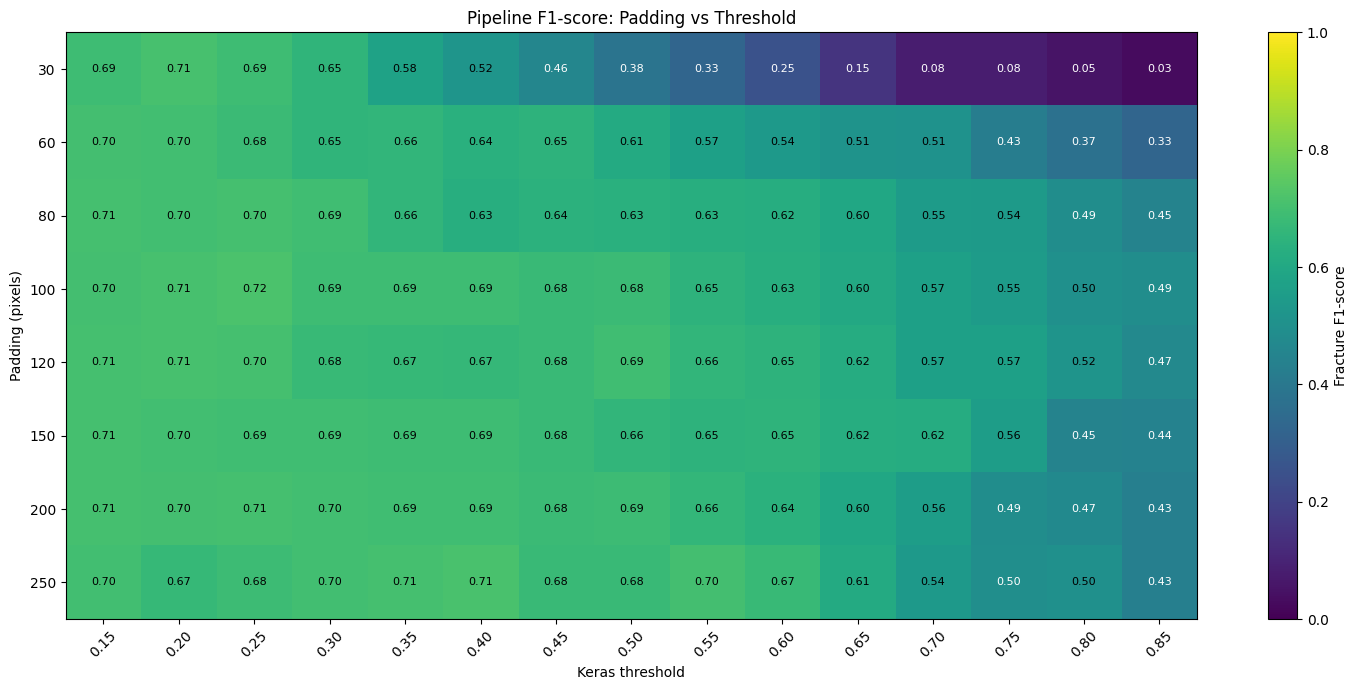


Spouštím inference: test
Zpracováno: 25/409
Zpracováno: 50/409
Zpracováno: 75/409
Zpracováno: 100/409
Zpracováno: 125/409
Zpracováno: 150/409
Zpracováno: 175/409
Zpracováno: 200/409
Zpracováno: 225/409
Zpracováno: 250/409
Zpracováno: 275/409
Zpracováno: 300/409
Zpracováno: 325/409
Zpracováno: 350/409
Zpracováno: 375/409
Zpracováno: 400/409

test dokončeno
Úspěšně: 409
Selhalo: 0
PIL fallback: 0

PŮVODNÍ PIPELINE
Padding: 30
Keras threshold: 0.50
Vyhodnoceno: 409 snímků

Classification report:
              precision    recall  f1-score   support

 No Fracture       0.88      0.98      0.93       337
    Fracture       0.81      0.40      0.54        72

    accuracy                           0.88       409
   macro avg       0.85      0.69      0.73       409
weighted avg       0.87      0.88      0.86       409

Confusion matrix:
[[330   7]
 [ 43  29]]

OPTIMALIZOVANÁ PIPELINE
Padding: 100
Keras threshold: 0.25
Vyhodnoceno: 409 snímků

Classification report:
              precision  

In [10]:

import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.efficientnet import preprocess_input
from ultralytics import YOLO
from PIL import Image, ImageFile
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import matplotlib.pyplot as plt

ImageFile.LOAD_TRUNCATED_IMAGES = True

# ============================================================
# 1. CESTY A NASTAVENÍ
# ============================================================

BASE_PATH = "/content/drive/MyDrive/BK2.0/FracAtlas2"

VAL_CSV = (
    "/content/drive/MyDrive/YOLO_undersample/"
    "universal_val_split.csv"
)

TEST_CSV = (
    "/content/drive/MyDrive/YOLO_undersample/"
    "universal_test_split.csv"
)

YOLO_PATH = (
    "/content/drive/MyDrive/YOLO_undersample/"
    "frac_atlas_seg_640_usample/weights/best.pt"
)

KERAS_PATH = (
    "/content/drive/MyDrive/KerasNET/"
    "efficientnet_best.keras"
)

OUTPUT_DIR = "/content/drive/MyDrive/pipeline_grid_search"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = (640, 640)
CONF_THRESHOLD = 0.05
TOP_K = 50

# Původní nastavení pro porovnání
PAD = 30
KERAS_TH = 0.5

# Hodnoty pro Grid Search
PADDINGS = [30, 60, 80, 100, 120, 150, 200, 250]
THRESHOLDS = np.round(np.arange(15, 86, 5) / 100, 2)

BATCH_SIZE = 4

# ============================================================
# 2. NAČTENÍ MODELŮ
# ============================================================

print("Načítám modely...")

yolo_model = YOLO(YOLO_PATH)
keras_model = keras.models.load_model(KERAS_PATH)

print("Modely načteny!")

# ============================================================
# 3. NAČTENÍ DATASETU
# ============================================================

def load_dataset(csv_path):

    df = pd.read_csv(csv_path)

    def get_full_path(row):
        folder = (
            "Fractured"
            if int(row["label"]) == 1
            else "Non_fractured"
        )

        return os.path.join(
            BASE_PATH,
            "images",
            folder,
            row["img_name"]
        )

    df["filepath"] = df.apply(get_full_path, axis=1)
    df["label"] = df["label"].astype(int)

    return df


val_df = load_dataset(VAL_CSV)
test_df = load_dataset(TEST_CSV)

# Kontrola překryvu validačních a testovacích dat
overlap = set(val_df["filepath"]) & set(test_df["filepath"])

if overlap:
    raise ValueError(
        f"Validation/test overlap: {len(overlap)} images"
    )

print(f"\nValidation: {len(val_df)}")
print(f"  Fractured: {(val_df['label'] == 1).sum()}")
print(f"  Healthy: {(val_df['label'] == 0).sum()}")

print(f"\nTest: {len(test_df)}")
print(f"  Fractured: {(test_df['label'] == 1).sum()}")
print(f"  Healthy: {(test_df['label'] == 0).sum()}")

# ============================================================
# 4. BEZPEČNÉ NAČTENÍ OBRÁZKU
# ============================================================

def load_image(img_path):

    # Nejprve OpenCV
    img = cv2.imread(img_path)

    if img is not None:
        return img, False

    # Fallback přes Pillow
    print(f"PIL fallback: {os.path.basename(img_path)}")

    try:
        with Image.open(img_path) as pil_img:
            rgb = np.array(pil_img.convert("RGB"))

        img = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

        return img, True

    except Exception as e:
        raise ValueError(
            f"Unable to read image: {img_path}"
        ) from e


# ============================================================
# 5. KERAS KLASIFIKACE CROPU
# ============================================================

def classify_crops(crops):

    probabilities = []

    for start in range(0, len(crops), BATCH_SIZE):

        batch_crops = crops[start:start + BATCH_SIZE]

        batch = np.stack([
            cv2.resize(crop, IMG_SIZE).astype(np.float32)
            for crop in batch_crops
        ])

        batch = preprocess_input(batch)

        preds = keras_model.predict(
            batch,
            verbose=0
        ).reshape(-1)

        probabilities.extend(preds.tolist())

    return probabilities


# ============================================================
# 6. YOLO -> CROPS -> KERAS
# ============================================================

def get_padding_scores(img_path, paddings):

    img, used_fallback = load_image(img_path)

    h, w = img.shape[:2]

    # YOLO dostává již načtený obrázek.
    # Neotevírá tedy znovu poškozený JPEG přes cestu.
    results = yolo_model(
        img,
        conf=CONF_THRESHOLD,
        verbose=False
    )

    if len(results) == 0:
        raise RuntimeError("YOLO returned no results")

    boxes = results[0].boxes

    scores = {pad: 0.0 for pad in paddings}

    # Žádná YOLO detekce = negativní predikce
    if boxes is None or len(boxes) == 0:
        return scores, used_fallback

    confidences = boxes.conf.detach().cpu().numpy()

    top_idx = np.argsort(confidences)[::-1][:TOP_K]

    coords = [
        tuple(
            map(
                int,
                boxes[int(i)].xyxy[0].cpu().numpy()
            )
        )
        for i in top_idx
    ]

    for pad in paddings:

        crops = []

        for x1, y1, x2, y2 in coords:

            # Padding kolem YOLO bounding boxu
            px1 = max(0, x1 - pad)
            py1 = max(0, y1 - pad)
            px2 = min(w, x2 + pad)
            py2 = min(h, y2 + pad)

            crop = img[py1:py2, px1:px2]

            if crop.size == 0:
                continue

            crop_rgb = cv2.cvtColor(
                crop,
                cv2.COLOR_BGR2RGB
            )

            crops.append(crop_rgb)

        if not crops:
            continue

        # Keras predikce všech cropů
        probabilities = classify_crops(crops)

        # Maximum odpovídá původnímu pravidlu:
        # stačí jeden crop nad thresholdem
        scores[pad] = max(probabilities)

    return scores, used_fallback


# ============================================================
# 7. VÝPOČET PRAVDĚPODOBNOSTÍ
# ============================================================

def evaluate_dataset(df, paddings, name):

    records = []
    failures = []
    fallback_images = []

    print(f"\nSpouštím inference: {name}")

    for idx, row in enumerate(df.itertuples(), start=1):

        try:
            scores, used_fallback = get_padding_scores(
                row.filepath,
                paddings
            )

            record = {
                "img_name": row.img_name,
                "label": int(row.label)
            }

            for pad, score in scores.items():
                record[f"pad_{pad}"] = score

            records.append(record)

            if used_fallback:
                fallback_images.append(row.img_name)

        except Exception as e:

            failures.append({
                "img_name": row.img_name,
                "label": int(row.label),
                "error": str(e)
            })

            print(f"FAILED: {row.img_name}: {e}")

        if idx % 25 == 0:
            print(f"Zpracováno: {idx}/{len(df)}")

    result_df = pd.DataFrame(records)

    result_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            f"{name}_probabilities.csv"
        ),
        index=False
    )

    pd.DataFrame(
        failures,
        columns=["img_name", "label", "error"]
    ).to_csv(
        os.path.join(OUTPUT_DIR, f"{name}_failures.csv"),
        index=False
    )

    pd.DataFrame({
        "img_name": fallback_images
    }).to_csv(
        os.path.join(OUTPUT_DIR, f"{name}_pil_fallback.csv"),
        index=False
    )

    print(f"\n{name} dokončeno")
    print(f"Úspěšně: {len(records)}")
    print(f"Selhalo: {len(failures)}")
    print(f"PIL fallback: {len(fallback_images)}")

    if result_df.empty:
        raise RuntimeError(f"No valid images in {name}")

    return result_df


# ============================================================
# 8. METRIKY
# ============================================================

def calculate_metrics(df, pad, threshold):

    y_true = df["label"].to_numpy()

    probabilities = df[f"pad_{pad}"].to_numpy()

    y_pred = (probabilities > threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {
        "padding": pad,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }


def print_report(df, pad, threshold, title):

    y_true = df["label"].to_numpy()

    probabilities = df[f"pad_{pad}"].to_numpy()

    y_pred = (probabilities > threshold).astype(int)

    print(f"\n{'='*55}")
    print(title)
    print(f"Padding: {pad}")
    print(f"Keras threshold: {threshold:.2f}")
    print(f"Vyhodnoceno: {len(df)} snímků")

    print("\nClassification report:")

    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["No Fracture", "Fracture"],
        zero_division=0
    ))

    print("Confusion matrix:")

    print(confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ))


# ============================================================
# 9. GRID SEARCH NA VALIDACI
# ============================================================

val_scores = evaluate_dataset(
    val_df,
    PADDINGS,
    "validation"
)

grid_results = []

for pad in PADDINGS:
    for threshold in THRESHOLDS:

        metrics = calculate_metrics(
            val_scores,
            pad,
            threshold
        )

        grid_results.append(metrics)

results_df = pd.DataFrame(grid_results)

results_df = results_df.sort_values(
    ["f1", "recall", "accuracy"],
    ascending=False
).reset_index(drop=True)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "grid_search_results.csv"),
    index=False
)

print("\nTOP 15 KOMBINACÍ NA VALIDACI")

print(
    results_df.head(15).to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

best = results_df.iloc[0]

BEST_PAD = int(best["padding"])
BEST_TH = float(best["threshold"])

print("\nNEJLEPŠÍ KOMBINACE NA VALIDACI")
print(f"Padding: {BEST_PAD}")
print(f"Threshold: {BEST_TH:.2f}")
print(f"Accuracy: {best['accuracy']:.4f}")
print(f"Precision: {best['precision']:.4f}")
print(f"Recall: {best['recall']:.4f}")
print(f"F1: {best['f1']:.4f}")
print(f"FN: {int(best['FN'])}")
print(f"FP: {int(best['FP'])}")

# ============================================================
# 10. HEATMAPA F1-SCORE
# ============================================================

pivot = results_df.pivot(
    index="padding",
    columns="threshold",
    values="f1"
)

fig, ax = plt.subplots(figsize=(15, 7))

im = ax.imshow(
    pivot.values,
    cmap="viridis",
    aspect="auto",
    vmin=0,
    vmax=1
)

ax.set_xticks(np.arange(len(pivot.columns)))
ax.set_xticklabels(
    [f"{x:.2f}" for x in pivot.columns],
    rotation=45
)

ax.set_yticks(np.arange(len(pivot.index)))
ax.set_yticklabels(pivot.index)

ax.set_xlabel("Keras threshold")
ax.set_ylabel("Padding (pixels)")
ax.set_title("Pipeline F1-score: Padding vs Threshold")

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):

        value = pivot.values[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value < 0.5 else "black"
        )

fig.colorbar(im, ax=ax, label="Fracture F1-score")

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "f1_heatmap.png"),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 11. FINÁLNÍ TESTOVÁNÍ
# ============================================================

# Testujeme jen původní a nejlepší padding.
test_paddings = sorted(set([PAD, BEST_PAD]))

test_scores = evaluate_dataset(
    test_df,
    test_paddings,
    "test"
)

# Původní nastavení
print_report(
    test_scores,
    PAD,
    KERAS_TH,
    "PŮVODNÍ PIPELINE"
)

# Nově nalezené nastavení
print_report(
    test_scores,
    BEST_PAD,
    BEST_TH,
    "OPTIMALIZOVANÁ PIPELINE"
)

# ============================================================
# 12. POROVNÁNÍ
# ============================================================

old_metrics = calculate_metrics(
    test_scores, PAD, KERAS_TH
)

new_metrics = calculate_metrics(
    test_scores, BEST_PAD, BEST_TH
)

comparison = pd.DataFrame([
    {"model": "Original", **old_metrics},
    {"model": "Optimized", **new_metrics}
])

print("\n========== FINAL COMPARISON ==========")

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "final_comparison.csv"),
    index=False
)

print(f"\nVýsledky uloženy do: {OUTPUT_DIR}")

print("\nPOZNÁMKA:")
print("Zkontroluj seznam selhaných snímků a PIL fallbacků.")
print("Metriky zahrnují jen úspěšně zpracované obrázky.")
